# 11 · Evaluation and pitfalls

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/11_evaluation_and_pitfalls.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 11 of 12*

A classifier is only as trustworthy as its evaluation. In notebook 10 every model scored above 85% accuracy —
but is accuracy the right number? Would a different split give the same answer? Did any information from
the test set sneak into training? In this notebook we use the **SMS Spam Collection** (where only about 13%
of messages are spam) and the newsgroups data to work through the metrics that matter — **precision,
recall, F1, macro vs micro averaging, precision–recall curves** — then **cross-validation**, **class
imbalance**, and the classic ways an evaluation fools you: **data leakage**, **duplicates** and **tuning on
the test set**.

### Learning objectives
By the end of this notebook you will be able to:
1. Explain why accuracy misleads on imbalanced data, and compute precision, recall and F1 from a confusion matrix.
2. Choose between macro, micro and weighted averaging for multi-class results.
3. Use a decision threshold and a precision–recall curve to trade false alarms against missed spam.
4. Estimate performance and its variability with stratified k-fold cross-validation inside a `Pipeline`.
5. Recognise and avoid data leakage: preprocessing fitted on test data, feature selection before splitting,
   duplicates across splits, and hyper-parameters tuned on the test set.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, GridSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, precision_recall_curve, average_precision_score,
                             roc_auc_score)

## 1 · The accuracy paradox
We split the SMS messages 75/25, **stratified** so that both parts keep the same spam proportion, and
start with the dumbest possible model: always predict the majority class, *ham*.

In [3]:
sms = nlp_course.load_sms()
print(sms["label"].value_counts(), "\n")
print(f"Spam share: {(sms['label'] == 'spam').mean():.1%}")
tr, te = train_test_split(sms, test_size=0.25, stratify=sms["label"], random_state=0)
y_tr = (tr["label"] == "spam").astype(int).to_numpy()   # 1 = spam (the positive class)
y_te = (te["label"] == "spam").astype(int).to_numpy()
print(f"train: {len(tr)} messages ({y_tr.mean():.1%} spam)   test: {len(te)} messages ({y_te.mean():.1%} spam)")

label
ham     4827
spam     747
Name: count, dtype: int64 

Spam share: 13.4%
train: 4180 messages (13.4% spam)   test: 1394 messages (13.4% spam)


In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(tr[["text"]], y_tr)
pred_dummy = dummy.predict(te[["text"]])
print(f"Always-ham accuracy: {accuracy_score(y_te, pred_dummy):.3f}")
print(f"Spam caught:         {pred_dummy[y_te == 1].sum()} of {y_te.sum()}")

Always-ham accuracy: 0.866
Spam caught:         0 of 187


A model that never catches a single spam message is "86.6% accurate". On imbalanced data accuracy mostly
measures the class balance. We need metrics that look at the class we care about.

## 2 · Confusion matrix, precision, recall and F1
Now a real model: TF-IDF + Logistic Regression, wrapped in a **`Pipeline`** so that the vectorizer is always
fitted on the training data only (more on this in section 6). With spam as the *positive* class:

| | predicted ham | predicted spam |
|---|---|---|
| **true ham** | TN (true negatives) | FP (false positives — a real message lost in the spam folder) |
| **true spam** | FN (false negatives — spam that got through) | TP (true positives) |

- **precision** = TP / (TP + FP): of the messages we flagged, how many were spam?
- **recall** = TP / (TP + FN): of the spam messages, how many did we catch?
- **F1** = 2 · precision · recall / (precision + recall): their harmonic mean, low if either is low.

In [5]:
pipe = make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(C=10, max_iter=2000))
pipe.fit(tr["text"], y_tr)
pred = pipe.predict(te["text"])
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
prec, rec = tp / (tp + fp), tp / (tp + fn)
f1 = 2 * prec * rec / (prec + rec)
print(f"by hand : accuracy={(tp + tn) / len(y_te):.3f}  precision={prec:.3f}  recall={rec:.3f}  F1={f1:.3f}")
print(f"sklearn : accuracy={accuracy_score(y_te, pred):.3f}  precision={precision_score(y_te, pred):.3f}  "
      f"recall={recall_score(y_te, pred):.3f}  F1={f1_score(y_te, pred):.3f}")

TN=1204  FP=3  FN=24  TP=163
by hand : accuracy=0.981  precision=0.982  recall=0.872  F1=0.924
sklearn : accuracy=0.981  precision=0.982  recall=0.872  F1=0.924


In [6]:
lr_prec, lr_rec, lr_f1 = prec, rec, f1
print(f"The model is right {prec:.1%} of the time when it says spam, but lets {fn} of {tp + fn} spam messages "
      f"({fn / (tp + fn):.1%}) through.")

The model is right 98.2% of the time when it says spam, but lets 24 of 187 spam messages (12.8%) through.


## 3 · Macro, micro and weighted averages
With several classes, per-class precision/recall/F1 must be averaged:
- **macro**: plain mean over classes — every class counts equally, so small classes matter.
- **micro**: pool all TP/FP/FN first — every *document* counts equally; for single-label problems micro-F1 = accuracy.
- **weighted**: mean over classes weighted by class size.

In [7]:
print(classification_report(y_te, pred, target_names=["ham", "spam"], digits=3))

              precision    recall  f1-score   support

         ham      0.980     0.998     0.989      1207
        spam      0.982     0.872     0.924       187

    accuracy                          0.981      1394
   macro avg      0.981     0.935     0.956      1394
weighted avg      0.981     0.981     0.980      1394



In [8]:
for avg in ["macro", "micro", "weighted"]:
    print(f"{avg:>8} F1: {f1_score(y_te, pred, average=avg):.3f}")
print(f"accuracy   : {accuracy_score(y_te, pred):.3f}")

   macro F1: 0.956
   micro F1: 0.981
weighted F1: 0.980
accuracy   : 0.981


On the imbalanced SMS data, the **micro** and **weighted** F1 are pulled up by the easy majority class (ham);
the **macro** F1 gives the spam class half the say and is therefore lower. On a roughly balanced problem —
like the 4 newsgroups — the three averages are almost identical (notebook 10). Report macro-F1 when every
class matters, and always show per-class numbers for imbalanced data.

## 4 · Thresholds and the precision–recall curve
`predict()` labels a message spam when $P(\text{spam}) \ge 0.5$. That 0.5 is a choice. Lowering the
threshold catches more spam (higher recall) but flags more real messages (lower precision). The
**precision–recall curve** shows every possible trade-off; its area is the **average precision (AP)**.

In [9]:
proba = pipe.predict_proba(te["text"])[:, 1]
P, R, T = precision_recall_curve(y_te, proba)
print(f"Average precision (area under the PR curve): {average_precision_score(y_te, proba):.3f}")
print(f"ROC AUC:                                    {roc_auc_score(y_te, proba):.3f}\n")
for t in [0.1, 0.2, 0.3, 0.5, 0.7]:
    p_t = (proba >= t).astype(int)
    print(f"threshold {t:.1f}: precision={precision_score(y_te, p_t):.3f}  recall={recall_score(y_te, p_t):.3f}  "
          f"flagged ham={((p_t == 1) & (y_te == 0)).sum():>2}  missed spam={((p_t == 0) & (y_te == 1)).sum():>2}")

Average precision (area under the PR curve): 0.970
ROC AUC:                                    0.989

threshold 0.1: precision=0.876  recall=0.941  flagged ham=25  missed spam=11
threshold 0.2: precision=0.929  recall=0.914  flagged ham=13  missed spam=16
threshold 0.3: precision=0.960  recall=0.909  flagged ham= 7  missed spam=17
threshold 0.5: precision=0.982  recall=0.872  flagged ham= 3  missed spam=24


threshold 0.7: precision=0.981  recall=0.813  flagged ham= 3  missed spam=35


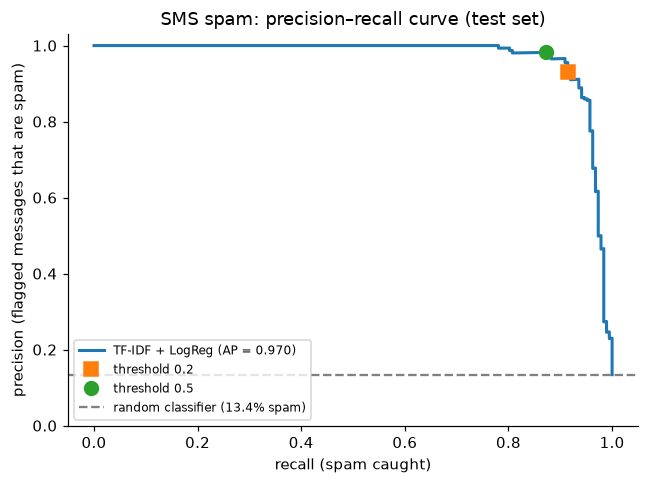

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(R, P, lw=2, label=f"TF-IDF + LogReg (AP = {average_precision_score(y_te, proba):.3f})")
for t, mk in [(0.2, "s"), (0.5, "o")]:
    p_t = (proba >= t).astype(int)
    ax.plot(recall_score(y_te, p_t), precision_score(y_te, p_t), mk, ms=9, label=f"threshold {t}")
ax.axhline(y_te.mean(), ls="--", c="grey", label=f"random classifier ({y_te.mean():.1%} spam)")
ax.set_xlabel("recall (spam caught)")
ax.set_ylabel("precision (flagged messages that are spam)")
ax.set_ylim(0, 1.03)
ax.set_title("SMS spam: precision–recall curve (test set)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(DOCS / "11_precision_recall.png", bbox_inches="tight")
plt.show()

ROC AUC is close to 1 for almost any decent model on imbalanced data, because the huge number of true
negatives keeps the false-positive *rate* tiny. The precision–recall curve and average precision focus on
the positive class and are the more honest summary when positives are rare.

## 5 · Class imbalance: re-weighting
Another lever is to make errors on the rare class cost more during training: `class_weight="balanced"`
weights each class inversely to its frequency.

In [11]:
rows = []
for name, clf in [("LogReg", LogisticRegression(C=10, max_iter=2000)),
                  ("LogReg balanced", LogisticRegression(C=10, max_iter=2000, class_weight="balanced")),
                  ("Linear SVM", LinearSVC()),
                  ("Linear SVM balanced", LinearSVC(class_weight="balanced")),
                  ("Naive Bayes", MultinomialNB(alpha=0.1))]:
    p = make_pipeline(TfidfVectorizer(sublinear_tf=True), clf).fit(tr["text"], y_tr).predict(te["text"])
    rows.append({"model": name, "accuracy": accuracy_score(y_te, p), "precision": precision_score(y_te, p),
                 "recall": recall_score(y_te, p), "F1": f1_score(y_te, p),
                 "ham flagged": int(((p == 1) & (y_te == 0)).sum()), "spam missed": int(((p == 0) & (y_te == 1)).sum())})
imb = pd.DataFrame(rows).set_index("model").round(3)
imb

,accuracy,precision,recall,F1,ham flagged,spam missed
model,,,,,,
LogReg,0.981,0.982,0.872,0.924,3,24
LogReg balanced,0.982,0.955,0.909,0.932,8,17
Linear SVM,0.981,0.971,0.882,0.924,5,22
Linear SVM balanced,0.980,0.954,0.893,0.923,8,20
Naive Bayes,0.982,1.000,0.866,0.928,0,25


Balancing the class weights trades precision for recall: more spam is caught, at the price of more real
messages flagged. Accuracy barely moves in any row — another reason not to judge imbalanced problems by
accuracy alone. Which trade-off is right is a **product decision** (how bad is a lost real message vs a
spam that gets through?), not a modelling one.

## 6 · Cross-validation: one split is one sample
The 1,394-message test set is a *sample*. Different random splits give different scores. **Stratified
k-fold cross-validation** splits the data into k folds, trains on k − 1 and tests on the remaining one, k
times, and reports the mean and spread. Using a `Pipeline` guarantees that the vectorizer is re-fitted on
the training folds each time.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
y_all = (sms["label"] == "spam").astype(int).to_numpy()
scores = cross_validate(make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(C=10, max_iter=2000)),
                        sms["text"], y_all, cv=cv, scoring=["accuracy", "f1", "recall", "precision"])
cvdf = pd.DataFrame({k[5:]: v for k, v in scores.items() if k.startswith("test_")})
print(cvdf.round(3))
print("\nmean ± std:")
for c in cvdf:
    print(f"  {c:>9}: {cvdf[c].mean():.3f} ± {cvdf[c].std():.3f}")

   accuracy     f1  recall  precision
0     0.988  0.955   0.919      0.993
1     0.986  0.944   0.906      0.985
2     0.978  0.914   0.847      0.992
3     0.984  0.937   0.887      0.993
4     0.986  0.944   0.913      0.978

mean ± std:
   accuracy: 0.984 ± 0.004
         f1: 0.939 ± 0.015
     recall: 0.894 ± 0.029
  precision: 0.988 ± 0.006


In [13]:
split_f1 = []
for seed in range(30):
    a, b = train_test_split(sms, test_size=0.25, stratify=sms["label"], random_state=seed)
    m = make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(C=10, max_iter=2000))
    m.fit(a["text"], a["label"] == "spam")
    split_f1.append(f1_score(b["label"] == "spam", m.predict(b["text"])))
split_f1 = np.array(split_f1)
print(f"Spam F1 over 30 random 75/25 splits: min {split_f1.min():.3f}, max {split_f1.max():.3f}, "
      f"mean {split_f1.mean():.3f} ± {split_f1.std():.3f}")

Spam F1 over 30 random 75/25 splits: min 0.905, max 0.964, mean 0.934 ± 0.014


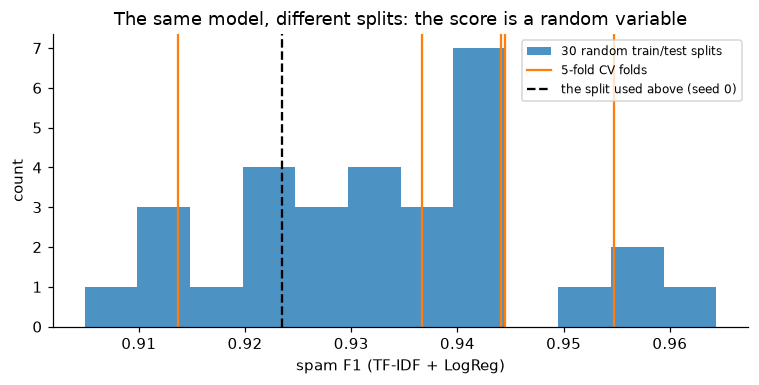

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(split_f1, bins=12, color="tab:blue", alpha=0.8, label="30 random train/test splits")
for k, v in enumerate(cvdf["f1"]):
    ax.axvline(v, color="tab:orange", lw=1.5, label="5-fold CV folds" if k == 0 else None)
ax.axvline(split_f1[0], color="black", ls="--", label="the split used above (seed 0)")
ax.set_xlabel("spam F1 (TF-IDF + LogReg)")
ax.set_ylabel("count")
ax.set_title("The same model, different splits: the score is a random variable")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DOCS / "11_split_variability.png", bbox_inches="tight")
plt.show()

The same model and the same data give spam F1 scores spread over several points depending only on the
split. Two models whose scores differ by less than this spread are not convincingly different. Report a
cross-validated mean ± standard deviation, not a single lucky (or unlucky) split.

## 7 · Data leakage
**Leakage** is any information from the evaluation data that reaches the model during training. It makes
results look better than they will be in real use. Three classic forms in text classification:

### 7a · Fitting the vectorizer on all the data
Fitting `TfidfVectorizer` on train + test lets the vocabulary and IDF weights see the test documents.

In [15]:
def evaluate(fit_texts):
    vec = TfidfVectorizer(sublinear_tf=True).fit(fit_texts)
    clf = LogisticRegression(C=10, max_iter=2000).fit(vec.transform(tr["text"]), y_tr)
    p = clf.predict(vec.transform(te["text"]))
    return len(vec.vocabulary_), f1_score(y_te, p)
for label, texts in [("train only (correct)", tr["text"]), ("train + test (leaky)", sms["text"])]:
    n, f = evaluate(texts)
    print(f"vectorizer fitted on {label:<22}: vocabulary {n:>5,}  spam F1 {f:.3f}")

vectorizer fitted on train only (correct)  : vocabulary 7,431  spam F1 0.924
vectorizer fitted on train + test (leaky)  : vocabulary 8,713  spam F1 0.908


Surprisingly, the leaky version scores *lower* here. Leakage does not always inflate a score — the classifier
is still trained only on training labels, and test-only words get a column but no useful weight. It is
still a bug: the vocabulary and IDF weights used in this evaluation are not the ones a deployed model
could have, so the number is not a valid estimate of real performance in either direction. Steps that
*use the labels* leak far more, and always in the flattering direction, as the next experiment shows.

### 7b · Feature selection before splitting
A dramatic demonstration: we replace the newsgroup labels by **random labels**. No model can genuinely beat
chance (25% for 4 classes). We then select the 200 words most associated with these random labels (chi²) —
once on **all** the data before cross-validation (leaky), and once inside a `Pipeline` so selection is
re-done on each training fold (correct).

In [16]:
news = nlp_course.load_newsgroups()
news["clean"] = news["text"].map(lambda s: " ".join(nlp_course.preprocess(s)))
rng = np.random.default_rng(0)
y_rand = rng.integers(0, 4, len(news))
cv4 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

X_news = TfidfVectorizer(min_df=2, sublinear_tf=True).fit_transform(news["clean"])
X_sel = SelectKBest(chi2, k=200).fit_transform(X_news, y_rand)            # sees ALL labels
leaky = cross_val_score(MultinomialNB(alpha=0.1), X_sel, y_rand, cv=cv4)

honest_pipe = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), SelectKBest(chi2, k=200), MultinomialNB(alpha=0.1))
honest = cross_val_score(honest_pipe, news["clean"], y_rand, cv=cv4)
print(f"Random labels, chance level = 0.250")
print(f"  selection before CV (leaky)  : accuracy {leaky.mean():.3f} ± {leaky.std():.3f}")
print(f"  selection inside pipeline    : accuracy {honest.mean():.3f} ± {honest.std():.3f}")

Random labels, chance level = 0.250
  selection before CV (leaky)  : accuracy 0.348 ± 0.011
  selection inside pipeline    : accuracy 0.248 ± 0.007


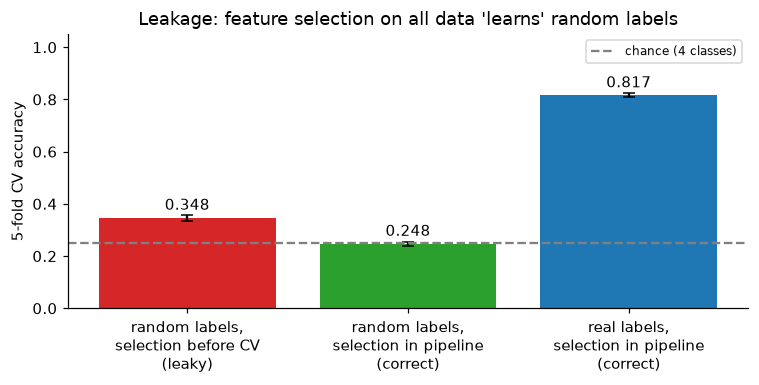

real labels, honest pipeline: 0.817 ± 0.008


In [17]:
true_y = news["category"].to_numpy()
real = cross_val_score(honest_pipe, news["clean"], true_y, cv=cv4)
fig, ax = plt.subplots(figsize=(7, 3.6))
names = ["random labels,\nselection before CV\n(leaky)", "random labels,\nselection in pipeline\n(correct)", "real labels,\nselection in pipeline\n(correct)"]
vals = [leaky.mean(), honest.mean(), real.mean()]
errs = [leaky.std(), honest.std(), real.std()]
bars = ax.bar(names, vals, yerr=errs, capsize=4, color=["tab:red", "tab:green", "tab:blue"])
for b_, v in zip(bars, vals):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.03, f"{v:.3f}", ha="center")
ax.axhline(0.25, ls="--", c="grey", label="chance (4 classes)")
ax.set_ylim(0, 1.05)
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Leakage: feature selection on all data 'learns' random labels")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DOCS / "11_leakage.png", bbox_inches="tight")
plt.show()
print(f"real labels, honest pipeline: {real.mean():.3f} ± {real.std():.3f}")

With leaky selection the model appears to "learn" pure noise well above chance: the 200 selected words were
chosen *because* they correlate with the random labels in the very documents used for testing. Inside the
pipeline the same procedure drops to chance level. Any step that looks at the labels — feature selection,
oversampling, target encoding, hyper-parameter search — must happen **inside** the training folds.

### 7c · Duplicates across train and test
Real corpora contain duplicates. If the same message is in both train and test, the model is tested on
text it has memorised.

In [18]:
n_dup = sms.duplicated("text").sum()
print(f"{n_dup} of {len(sms)} SMS messages ({n_dup / len(sms):.1%}) are exact duplicates of an earlier message")
for lab in ["spam", "ham"]:
    part = sms[sms["label"] == lab]
    print(f"  among {lab:<4}: {part.duplicated('text').sum()} of {len(part)} ({part.duplicated('text').mean():.1%})")
seen = set(tr["text"])
in_train = te["text"].isin(seen).to_numpy()
print(f"\nTest messages whose exact text also appears in the training set: {in_train.sum()} of {len(te)} "
      f"({y_te[in_train].sum()} of them spam)")

403 of 5574 SMS messages (7.2%) are exact duplicates of an earlier message
  among spam: 94 of 747 (12.6%)
  among ham : 309 of 4827 (6.4%)

Test messages whose exact text also appears in the training set: 144 of 1394 (31 of them spam)


In [19]:
p_seen, p_new = pred[in_train], pred[~in_train]
print(f"spam recall on test messages ALSO in train : {recall_score(y_te[in_train], p_seen):.3f}  (n spam = {y_te[in_train].sum()})")
print(f"spam recall on genuinely new test messages : {recall_score(y_te[~in_train], p_new):.3f}  (n spam = {y_te[~in_train].sum()})")

dedup = sms.drop_duplicates("text")
y_dd = (dedup["label"] == "spam").astype(int).to_numpy()
cv_dd = cross_val_score(make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(C=10, max_iter=2000)),
                        dedup["text"], y_dd, cv=cv, scoring="f1")
print(f"\n5-fold CV spam F1 with duplicates   : {cvdf['f1'].mean():.3f} ± {cvdf['f1'].std():.3f}  ({len(sms)} messages)")
print(f"5-fold CV spam F1 after de-duplication: {cv_dd.mean():.3f} ± {cv_dd.std():.3f}  ({len(dedup)} messages)")

spam recall on test messages ALSO in train : 1.000  (n spam = 31)
spam recall on genuinely new test messages : 0.846  (n spam = 156)



5-fold CV spam F1 with duplicates   : 0.939 ± 0.015  (5574 messages)
5-fold CV spam F1 after de-duplication: 0.928 ± 0.015  (5171 messages)


Spam campaigns send the same text many times, so duplicates are about twice as common among spam as among
ham. The model catches every test spam it has already seen verbatim in training, but noticeably less of the
genuinely new spam, and the cross-validated F1 drops slightly once duplicates are removed.
**De-duplicate before splitting** (or split by group, e.g. by sender or by thread) so that the test set
measures generalisation, not memory.

### 7d · Tuning on the test set
Trying many settings and keeping the one with the best *test* score turns the test set into a training
set. Tune with cross-validation on the training data only (`GridSearchCV`), then evaluate the single chosen
model **once** on the test set.

In [20]:
grid = GridSearchCV(
    make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(max_iter=2000)),
    {"tfidfvectorizer__ngram_range": [(1, 1), (1, 2)], "logisticregression__C": [1, 10, 100]},
    cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1")
grid.fit(tr["text"], y_tr)
print("best parameters (chosen on the training folds):", grid.best_params_)
print(f"cross-validated F1 of that choice: {grid.best_score_:.3f}")
print(f"test F1, measured once:            {f1_score(y_te, grid.predict(te['text'])):.3f}")

best parameters (chosen on the training folds): {'logisticregression__C': 100, 'tfidfvectorizer__ngram_range': (1, 2)}
cross-validated F1 of that choice: 0.945
test F1, measured once:            0.930


The test score is the one number we report; the cross-validated score is what we used for choosing. If
you then go back and change the model because of the test score, the test set is no longer unseen — you
would need a fresh one.

## 8 · Honest caveats
Even a carefully evaluated model has limits that no metric on this test set reveals:
- **Distribution shift.** The SMS messages come from one collection; newsgroup posts from 1993. New spam
  campaigns, new topics and new vocabulary will lower real-world performance.
- **Label noise.** Some labels in public datasets are wrong or debatable; a 98% score may hit the ceiling of the labels.
- **Small test sets.** With 187 spam messages in the test set, one more or one fewer caught spam moves recall by
  about half a percentage point — differences of that size are noise.
- **The metric is a proxy.** The real cost of a lost message and of a missed spam is set by users, not by F1.

## Exercises
**Exercise 1.** A spam filter is tested on 1,000 messages, 100 of them spam. It flags 90 messages, of which
80 are spam. Compute accuracy, precision, recall and F1 by hand (in Python), then check them with scikit-learn
on synthetic label arrays.

In [21]:
# your code here

<details>
<summary><b>Show solution</b></summary>

TN = 1000 − 80 − 10 − 20 = 890. Accuracy is 0.970 even though one spam in five gets through.

```python
tp, fp = 80, 10
fn = 100 - tp
tn = 1000 - tp - fp - fn
acc = (tp + tn) / 1000
prec, rec = tp / (tp + fp), tp / (tp + fn)
print(f"by hand : acc={acc:.3f} precision={prec:.3f} recall={rec:.3f} F1={2 * prec * rec / (prec + rec):.3f}")
y_true = np.array([1] * tp + [0] * fp + [1] * fn + [0] * tn)
y_pred = np.array([1] * tp + [1] * fp + [0] * fn + [0] * tn)
print(f"sklearn : acc={accuracy_score(y_true, y_pred):.3f} precision={precision_score(y_true, y_pred):.3f} "
      f"recall={recall_score(y_true, y_pred):.3f} F1={f1_score(y_true, y_pred):.3f}")
```
</details>

In [22]:
tp, fp = 80, 10
fn = 100 - tp
tn = 1000 - tp - fp - fn
acc = (tp + tn) / 1000
prec, rec = tp / (tp + fp), tp / (tp + fn)
print(f"by hand : acc={acc:.3f} precision={prec:.3f} recall={rec:.3f} F1={2 * prec * rec / (prec + rec):.3f}")
y_true = np.array([1] * tp + [0] * fp + [1] * fn + [0] * tn)
y_pred = np.array([1] * tp + [1] * fp + [0] * fn + [0] * tn)
print(f"sklearn : acc={accuracy_score(y_true, y_pred):.3f} precision={precision_score(y_true, y_pred):.3f} "
      f"recall={recall_score(y_true, y_pred):.3f} F1={f1_score(y_true, y_pred):.3f}")

by hand : acc=0.970 precision=0.889 recall=0.800 F1=0.842
sklearn : acc=0.970 precision=0.889 recall=0.800 F1=0.842


**Exercise 2.** Using `proba` from section 4, find the **highest** threshold that still catches at least 95%
of the test spam. What precision and how many flagged ham messages does it cost? (Strictly, the threshold
should be chosen on validation data, not on the test set — see 7d.)

In [23]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Moving along the precision–recall curve: catching 95% of spam requires a threshold well below 0.5, and precision drops accordingly.

```python
ok = [t for t in np.unique(proba) if recall_score(y_te, (proba >= t).astype(int)) >= 0.95]
t95 = max(ok)
p95 = (proba >= t95).astype(int)
print(f"threshold {t95:.3f}: recall={recall_score(y_te, p95):.3f}  precision={precision_score(y_te, p95):.3f}  "
      f"ham flagged={((p95 == 1) & (y_te == 0)).sum()}")
```
</details>

In [24]:
ok = [t for t in np.unique(proba) if recall_score(y_te, (proba >= t).astype(int)) >= 0.95]
t95 = max(ok)
p95 = (proba >= t95).astype(int)
print(f"threshold {t95:.3f}: recall={recall_score(y_te, p95):.3f}  precision={precision_score(y_te, p95):.3f}  "
      f"ham flagged={((p95 == 1) & (y_te == 0)).sum()}")

threshold 0.091: recall=0.952  precision=0.860  ham flagged=29


**Exercise 3.** Repeat the random-label experiment of section 7b with `k` (the number of selected words)
in `[10, 50, 200, 1000, 5000]`, for both the leaky and the correct procedure. How does the leaky accuracy
depend on `k`?

In [25]:
# your code here

<details>
<summary><b>Show solution</b></summary>

The correct procedure stays near chance (about 0.25) for every k. The leaky accuracy grows with k — from 0.270 at k=10 to 0.477 at k=1000 — and falls back a little at k=5000, where most selected words are no longer the ones most correlated with the noise.

```python
for k in [10, 50, 200, 1000, 5000]:
    Xs = SelectKBest(chi2, k=k).fit_transform(X_news, y_rand)
    lk = cross_val_score(MultinomialNB(alpha=0.1), Xs, y_rand, cv=cv4).mean()
    ok_ = cross_val_score(make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), SelectKBest(chi2, k=k),
                                        MultinomialNB(alpha=0.1)), news["clean"], y_rand, cv=cv4).mean()
    print(f"k={k:>5}: leaky {lk:.3f}   correct {ok_:.3f}")
```
</details>

In [26]:
for k in [10, 50, 200, 1000, 5000]:
    Xs = SelectKBest(chi2, k=k).fit_transform(X_news, y_rand)
    lk = cross_val_score(MultinomialNB(alpha=0.1), Xs, y_rand, cv=cv4).mean()
    ok_ = cross_val_score(make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), SelectKBest(chi2, k=k),
                                        MultinomialNB(alpha=0.1)), news["clean"], y_rand, cv=cv4).mean()
    print(f"k={k:>5}: leaky {lk:.3f}   correct {ok_:.3f}")

k=   10: leaky 0.270   correct 0.262


k=   50: leaky 0.290   correct 0.258


k=  200: leaky 0.348   correct 0.248


k= 1000: leaky 0.477   correct 0.243


k= 5000: leaky 0.435   correct 0.246


## Summary
- On imbalanced data accuracy is dominated by the majority class: an always-ham model is 86.6% accurate.
- **Precision** asks "how many flagged are right?", **recall** "how many positives did we catch?", **F1** combines them.
- **Macro** averaging treats classes equally; **micro** averaging equals accuracy for single-label problems.
- The decision threshold and `class_weight="balanced"` trade precision against recall; the
  **precision–recall curve** shows all trade-offs.
- A single split is noisy: use **stratified k-fold cross-validation** and report mean ± std.
- Avoid **leakage**: fit every step on training data only (use a `Pipeline`), de-duplicate before splitting,
  and tune with cross-validation, never on the test set.

**Next:** [12 · Mini project and recap](12_mini_project_and_recap.ipynb).